In [1]:
import os

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
from astropy.coordinates import SkyCoord
from astropy.io import fits
from gammapy.irf import load_irf_dict_from_file, EnergyDependentMultiGaussPSF
from scipy.stats import chi2, poisson
from scipy.optimize import curve_fit, least_squares, nnls, brentq

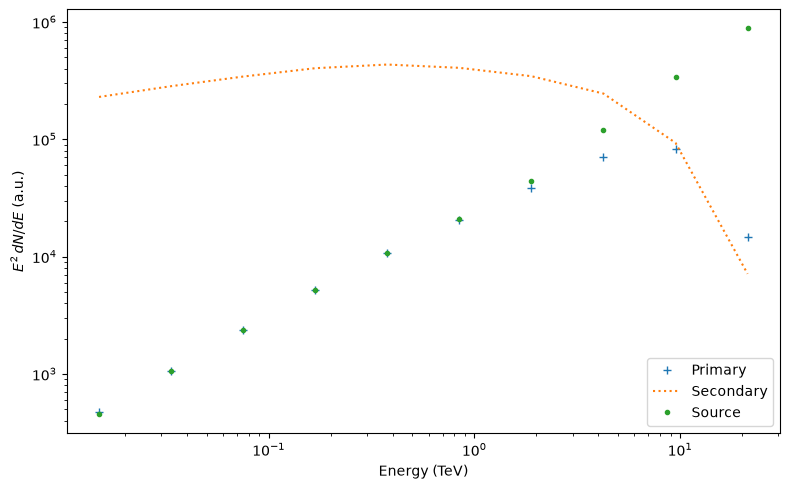

src_counts= 254434
end_counts= 27182715.162729897


In [2]:
# TODO: MRK421
data = np.genfromtxt("../jeffrey_crbeam/MRK501_B0")

dist = 152.6*3261563.7769443 # Mpc to ly

dict_data = {'energy': data[:, 0],
             'source_energy': data[:, 1],
             'weight': data[:, 2],
             'x': data[:, 3],
             'y': data[:, 4],
             'z': data[:, 5],
             'x_final': data[:, 6],
             'y_final': data[:, 7],
             'z_final': data[:, 8],
             'px': data[:, 9],
             'py': data[:, 10],
             'pz': data[:, 11],
             'theta': data[:, 12],
             'phi': data[:, 13],
             't_delay': data[:, 14]*dist,  # convert to light years
             'redshift': data[:, 15],
             'prim': data[:, 16]}

prim = np.asarray(dict_data["prim"], dtype=float)
energies = np.asarray(dict_data["energy"], dtype=float) / 1e12  # TeV
weights = np.asarray(dict_data["weight"], dtype=float)
source_energies = np.asarray(dict_data["source_energy"], dtype=float) / 1e12

valid_energies = energies[np.isfinite(energies) & (energies > 0)]
if valid_energies.size == 0:
    raise ValueError("No finite, positive event energies found.")
    
e_bins = np.logspace(
    np.log10(valid_energies.min()),
    np.log10(valid_energies.max()),
    11,
)
e = np.sqrt(e_bins[:-1] * e_bins[1:])
de = np.diff(e_bins)

prim_mask = prim == 1
sec_mask = prim != 1

counts_prim, _ = np.histogram(
    energies[prim_mask], bins=e_bins, weights=weights[prim_mask]
)
counts_sec, _ = np.histogram(
    energies[sec_mask], bins=e_bins, weights=weights[sec_mask]
)
counts_source, _ = np.histogram(source_energies, bins=e_bins)

sed_prim = e**2 * counts_prim / de
sed_sec = e**2 * counts_sec / de
sed_source = e**2 * counts_source / de

plt.figure(figsize=(8, 5))
plt.plot(e, sed_prim, "+", label=f"Primary")
plt.plot(e, sed_sec, ":", label=f"Secondary")
plt.plot(e, sed_source, ".", label=f"Source")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Energy (TeV)")
plt.ylabel(r"$E^2\,dN/dE$ (a.u.)")
plt.legend()
plt.tight_layout()
plt.show()

print("src_counts=", np.sum(counts_source))
print("end_counts=", np.sum(counts_prim) + np.sum(counts_sec))


In [3]:
# LHAASO MRK501 values
def exponential_corr_powerlaw(e, F0, alpha, Ecut):
    return F0*e**(-alpha)*np.exp(-e/Ecut)

F0 = 10.89e-12  # TeV^-1 cm^-2 s^-1
F0_UP = (10.89 + 0.31) * 1e-12
F0_DOWN = (10.89 - 0.31) * 1e-12

alpha = 2.18
alpha_UP = 2.18 + 0.04
alpha_DOWN = 2.18 - 0.04

Ecut = 9.51  # TeV
Ecut_UP = 9.51 + 1.44
Ecut_DOWN = 9.51 - 1.44

F0_values = [F0_DOWN, F0, F0_UP]
alpha_values = [alpha_DOWN, alpha, alpha_UP]
Ecut_values = [Ecut_DOWN, Ecut, Ecut_UP]

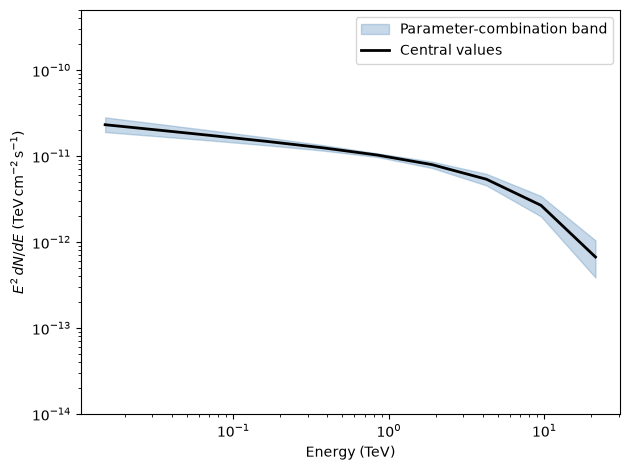

In [4]:

curves = []
for f0 in F0_values:
    for a in alpha_values:
        for ec in Ecut_values:
            curves.append(e**2 * exponential_corr_powerlaw(e, f0, a, ec))

curves = np.array(curves)
lower = curves.min(axis=0)
upper = curves.max(axis=0)

central = e**2 * exponential_corr_powerlaw(e, F0, alpha, Ecut)

plt.fill_between(e, lower, upper, color="steelblue", alpha=0.3,
                 label="Parameter-combination band")
plt.plot(e, central, color="black", linewidth=2, label="Central values")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Energy (TeV)")
plt.ylabel(r"$E^2\,dN/dE$ $(\mathrm{TeV\,cm^{-2}\,s^{-1}})$")
plt.ylim(1e-14, 5e-10)
plt.legend()
plt.tight_layout()
plt.show()


In [5]:
weights_up = weights.copy()
weights_central = weights.copy()
weights_down = weights.copy()

final_segment_mask = np.zeros(source_energies.shape, dtype=bool)

for i, (lo, hi) in enumerate(zip(e[:-1], e[1:])):
    segment_mask = (
        np.isfinite(source_energies)
        & (source_energies >= lo)
        & (source_energies < hi)
    )
    final_segment_mask |= segment_mask

    if (
        not np.isfinite(sed_source[i])
        or sed_source[i] == 0
        or not np.isfinite(lower[i])
        or not np.isfinite(central[i])
        or not np.isfinite(upper[i])
    ):
        continue

    weights_down[segment_mask] *= lower[i] / sed_source[i]
    weights_central[segment_mask] *= central[i] / sed_source[i]
    weights_up[segment_mask] *= upper[i] / sed_source[i]

# Restrict to secondary events whose source energies fall in the selected bins
final_mask = sec_mask & final_segment_mask

counts_down, _ = np.histogram(
    energies[final_mask], bins=e_bins, weights=weights_down[final_mask]
)
counts_central, _ = np.histogram(
    energies[final_mask], bins=e_bins, weights=weights_central[final_mask]
)
counts_up, _ = np.histogram(
    energies[final_mask], bins=e_bins, weights=weights_up[final_mask]
)

bin_widths = np.diff(e_bins)
bin_centers = np.sqrt(e_bins[:-1] * e_bins[1:])

sed_down = bin_centers**2 * counts_down / bin_widths
sed_central = bin_centers**2 * counts_central / bin_widths
sed_up = bin_centers**2 * counts_up / bin_widths


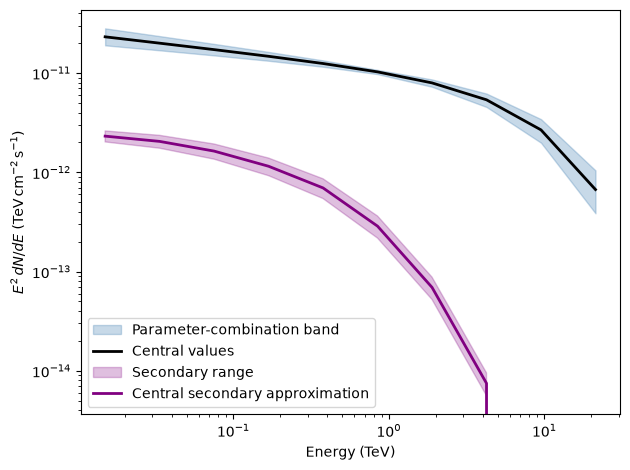

In [6]:
curves = []
for f0 in F0_values:
    for a in alpha_values:
        for ec in Ecut_values:
            curves.append(
                e**2 * exponential_corr_powerlaw(e, f0, a, ec)
            )

curves = np.array(curves)
lower = curves.min(axis=0)
upper = curves.max(axis=0)

plt.fill_between(
    e, lower, upper,
    color="steelblue", alpha=0.3,
    label="Parameter-combination band"
)
plt.plot(e, central, color="black", linewidth=2, label="Central values")

plt.fill_between(
    bin_centers, sed_down, sed_up,
    color="purple", alpha=0.25,
    label="Secondary range"
)
plt.plot(
    bin_centers, sed_central,
    color="purple", linewidth=2,
    label="Central secondary approximation"
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Energy (TeV)")
plt.ylabel(r"$E^2\,dN/dE$ $(\mathrm{TeV\,cm^{-2}\,s^{-1}})$")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
np.savez(
    "sec_approx_mrk501.npz",
    e=bin_centers,
    sed_up=sed_up,
    sed_down=sed_down,
    sed_central=sed_central,
    ratio_central=sed_central/central,
    ratio_up=sed_up/lower,
    ratio_down=sed_down/upper,
)